In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import ceil, log10
from collections import deque
np.set_printoptions(precision=4, suppress=True)

technique,CDMA,FDMA,OFDMA,SDMA,TDMA
deployment,,,,,
D1_cellular_voice,3.25,3.00,3.80,2.75,3.10
D2_tactical,3.90,2.15,2.70,2.85,2.15
D3_stadium,3.30,2.85,4.05,2.65,3.00
D4_sensors,2.65,2.05,2.80,2.15,2.45


,deployment,base_winner,winner_flips,tests
0,D1_cellular_voice,OFDMA,0,12
1,D2_tactical,CDMA,0,12
2,D3_stadium,OFDMA,0,12
3,D4_sensors,OFDMA,0,12


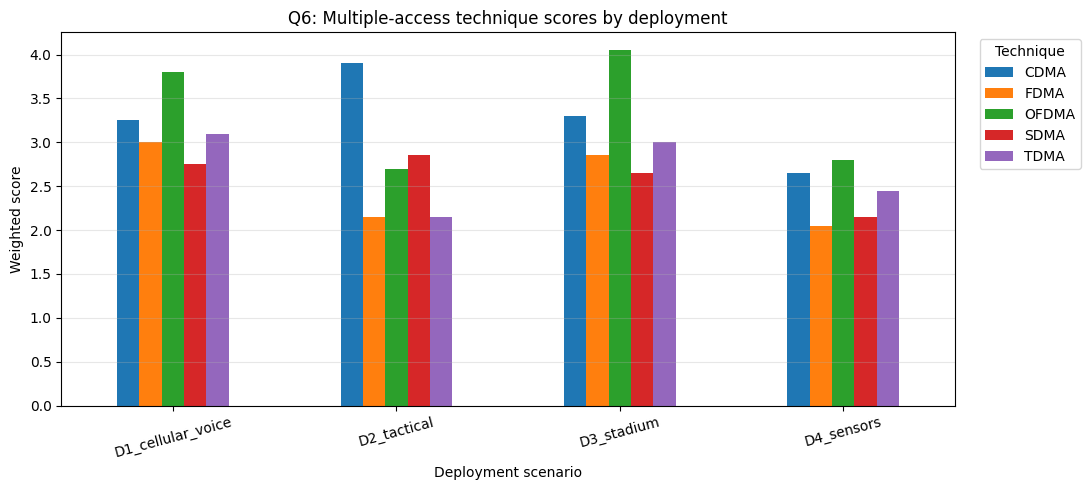

In [2]:
techniques=["SDMA","TDMA","FDMA","CDMA","OFDMA"]
criteria=["Capacity","Bursty_efficiency","Robustness","Simplicity","Scalability","QoS_fairness"]
# Base ratings transcribed from the report's evidence-based rating table.
base=np.array([
 [4,3,3,1,2,3],  # SDMA
 [3,2,3,3,3,4],  # TDMA
 [3,1,3,4,2,4],  # FDMA
 [3,3,5,2,3,3],  # CDMA
 [5,4,4,2,4,3]   # OFDMA
],dtype=float)
weights={
 "D1_cellular_voice":[.25,.05,.20,.15,.20,.15],
 "D2_tactical":[.10,.05,.50,.10,.05,.20],
 "D3_stadium":[.35,.10,.20,.10,.15,.10],
 "D4_sensors":[.05,.35,.10,.20,.25,.05]
}
# Deployment-specific rating adjustments described in the report.
ratings={k:base.copy() for k in weights}
ratings["D2_tactical"][2,2]=1  # TDMA robustness
ratings["D2_tactical"][1,2]=1  # FDMA robustness
ratings["D2_tactical"][4,2]=2  # OFDMA robustness
ratings["D3_stadium"][0,0]=3
ratings["D4_sensors"][2,4]=1
ratings["D4_sensors"][1,4]=2
ratings["D4_sensors"][3,1]=2
ratings["D4_sensors"][0,4]=1
ratings["D4_sensors"][4,3]=1
ratings["D4_sensors"][4,4]=3
ratings["D4_sensors"][4,1]=3

score_rows=[]
for dep,w in weights.items():
    scores=ratings[dep]@np.array(w)
    for tech,score in zip(techniques,scores):
        score_rows.append([dep,tech,score])
q6=pd.DataFrame(score_rows,columns=["deployment","technique","weighted_score"])
display(q6.pivot(index="deployment",columns="technique",values="weighted_score").round(3))
q6.to_csv("q6_scores.csv",index=False)

# Sensitivity: independently perturb one criterion weight by +/-20%, renormalise.
sens=[]
rng=np.random.default_rng(606)
for dep,w0 in weights.items():
    w0=np.array(w0,dtype=float)
    base_scores=ratings[dep]@w0
    base_winner=techniques[int(np.argmax(base_scores))]
    flips=0
    for i in range(len(w0)):
        for mult in (0.8,1.2):
            w=w0.copy(); w[i]*=mult; w/=w.sum()
            winner=techniques[int(np.argmax(ratings[dep]@w))]
            flips += winner!=base_winner
    sens.append([dep,base_winner,flips,12])
q6_sensitivity=pd.DataFrame(sens,columns=["deployment","base_winner","winner_flips","tests"])
display(q6_sensitivity)
q6_sensitivity.to_csv("q6_sensitivity.csv",index=False)

# Visualisation: weighted decision scores for every deployment
q6_pivot = q6.pivot(index="deployment", columns="technique", values="weighted_score")
ax = q6_pivot.plot(kind="bar", figsize=(11,5))
ax.set_ylabel("Weighted score")
ax.set_xlabel("Deployment scenario")
ax.set_title("Q6: Multiple-access technique scores by deployment")
ax.tick_params(axis="x", rotation=15)
ax.grid(axis="y", alpha=.3)
ax.legend(title="Technique", bbox_to_anchor=(1.02,1), loc="upper left")
plt.tight_layout()
plt.show()
